Huidige map: c:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision
Aantal afbeeldingen: 240


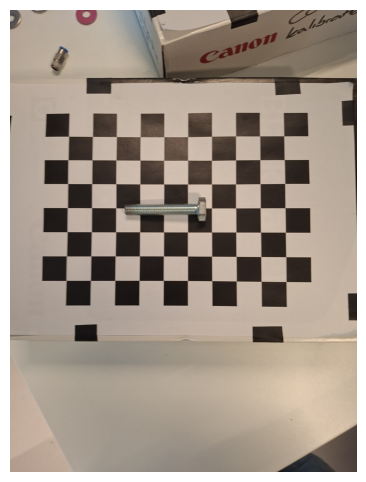

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Controleer waar het notebook wordt uitgevoerd
print("Huidige map:", Path.cwd())

# Locatie van de afbeeldingen
DATASET_PATH = Path("dataset/images")

# Zoek afbeeldingen
image_paths = sorted(DATASET_PATH.glob("*.jpg"))

print("Aantal afbeeldingen:", len(image_paths))

if len(image_paths) > 0:
    image = cv2.imread(str(image_paths[180]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print("Geen afbeeldingen gevonden! Controleer het pad.")

Aantal gelabelde objecten: 1


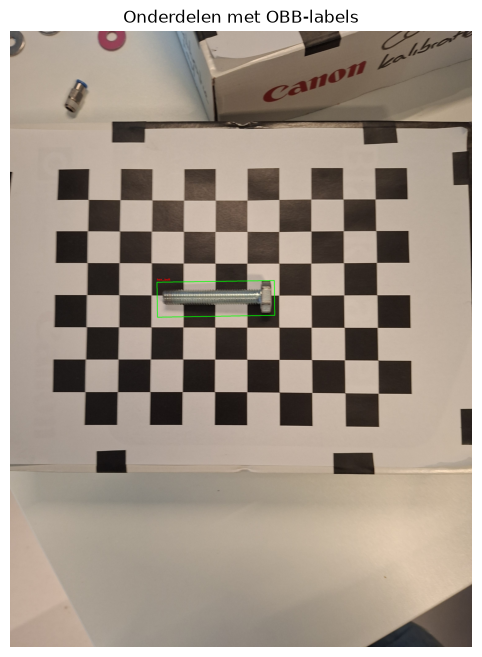

In [23]:
LABEL_PATH = Path("dataset/labels")

# Gebruik dezelfde afbeelding als blok 1
img_path = image_paths[180]

# Bijbehorend labelbestand
label_path = LABEL_PATH / f"{img_path.stem}.txt"

result = image.copy()
h, w = image.shape[:2]

objecten = []

klassen = {
    0: "hex_nut",
    1: "washer",
    2: "allen_screw",
    3: "hex_bolt",
    4: "carriage_bolt",
    5: "barrel_nut",
    6: "pneumatic_fitting"
}

if label_path.exists():

    for regel in label_path.read_text().splitlines():

        waarden = list(map(float, regel.split()))

        klasse = int(waarden[0])

        # Vier hoekpunten van het object
        punten = np.array(waarden[1:9]).reshape(4, 2)

        punten[:, 0] *= w
        punten[:, 1] *= h

        punten = punten.astype(np.int32)

        objecten.append((klasse, punten))

        # Bounding box tekenen
        cv2.polylines(result, [punten], True, (0, 255, 0), 3)

        # Klassenaam weergeven
        x, y = punten[0]

        cv2.putText(
            result,
            klassen[klasse],
            (int(x), int(y) - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2
        )

    print("Aantal gelabelde objecten:", len(objecten))

else:
    print("Geen labelbestand gevonden:", label_path)


plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.title("Onderdelen met OBB-labels")
plt.axis("off")
plt.show()

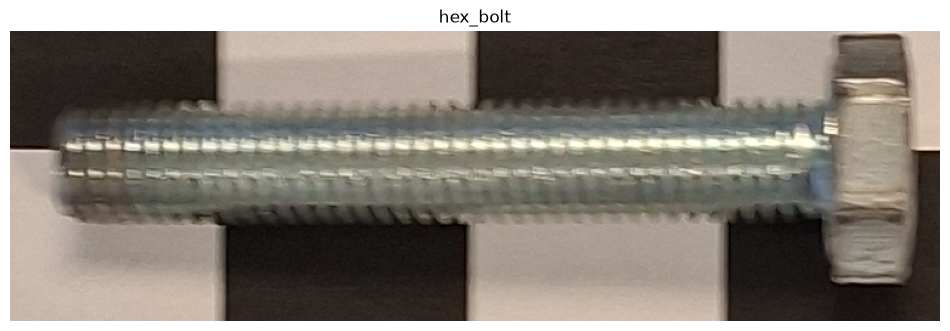

In [24]:
uitsneden = []

for klasse, punten in objecten:

    # Kleinste rechthoek rondom het object
    x, y, breedte, hoogte = cv2.boundingRect(punten)

    # Onderdeel uitsnijden
    crop = image[y:y+hoogte, x:x+breedte]

    if crop.size == 0:
        continue

    uitsneden.append((klasse, crop))

# Uitsneden weergeven
fig, assen = plt.subplots(
    1,
    max(1, len(uitsneden)),
    figsize=(12, 4),
    squeeze=False
)

for ax in assen.flat:
    ax.axis("off")

for ax, (klasse, crop) in zip(assen.flat, uitsneden):
    ax.imshow(crop)
    ax.set_title(klassen[klasse])

plt.show()

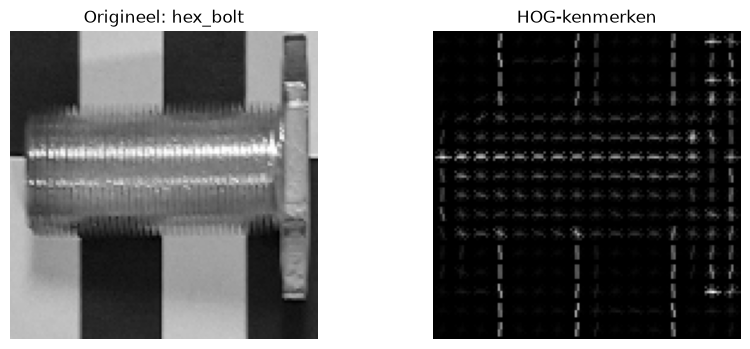

Aantal geanalyseerde onderdelen: 1


In [25]:
from skimage.feature import hog

hog_kenmerken = []

for klasse, crop in uitsneden:

    # Omzetten naar grijswaarden
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)

    # Alle afbeeldingen dezelfde grootte geven
    gray = cv2.resize(gray, (128, 128))

    # HOG-kenmerken berekenen
    kenmerken, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True
    )

    hog_kenmerken.append((klasse, kenmerken))

    # Resultaat weergeven
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(gray, cmap="gray")
    plt.title(f"Origineel: {klassen[klasse]}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(hog_image, cmap="gray")
    plt.title("HOG-kenmerken")
    plt.axis("off")

    plt.show()

print("Aantal geanalyseerde onderdelen:", len(hog_kenmerken))

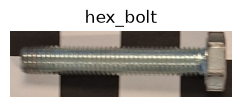

In [26]:
crops = []

def crop_obb(img, punten):
    punten = punten.astype(np.float32)

    # Lengte van de zijden bepalen
    breedte = np.linalg.norm(punten[1] - punten[0])
    hoogte = np.linalg.norm(punten[2] - punten[1])

    # Langste zijde horizontaal maken
    if hoogte > breedte:
        punten = np.roll(punten, -1, axis=0)
        breedte, hoogte = hoogte, breedte

    breedte = max(1, int(round(breedte)))
    hoogte = max(1, int(round(hoogte)))

    bestemming = np.array([
        [0, 0],
        [breedte - 1, 0],
        [breedte - 1, hoogte - 1],
        [0, hoogte - 1]
    ], dtype=np.float32)

    # Perspectiefcorrectie
    M = cv2.getPerspectiveTransform(punten, bestemming)

    crop = cv2.warpPerspective(
        img,
        M,
        (breedte, hoogte)
    )

    return crop

plt.figure(figsize=(12, 4))

for i, (klasse, punten) in enumerate(objecten[:5]):

    crop = crop_obb(image, punten)

    plt.subplot(1, 5, i + 1)
    plt.imshow(crop)
    plt.title(klassen[klasse])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
X = []
y = []
groepen = []

for img_path in image_paths:

    label_path = Path("dataset/labels") / f"{img_path.stem}.txt"

    if not label_path.exists():
        continue

    img = cv2.imread(str(img_path))

    if img is None:
        continue

    h, w = img.shape[:2]

    for regel in label_path.read_text().splitlines():

        waarden = list(map(float, regel.split()))
        klasse = int(waarden[0])

        punten = np.array(waarden[1:9]).reshape(4, 2)
        punten[:, 0] *= w
        punten[:, 1] *= h

        # Bounding box
        crop = crop_obb(img, punten)

        if crop.size == 0:
            continue

        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
        gray = cv2.resize(gray, (128, 128))

        kenmerken = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2)
        )

        X.append(kenmerken)
        y.append(klasse)
        crops.append(cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB))
        # Gespiegelde foto's bij dezelfde groep houden
        naam = img_path.stem
        for suffix in ("_hv_flip", "_h_flip", "_v_flip"):
            if naam.endswith(suffix):
                naam = naam[:-len(suffix)]
                break

        groepen.append(naam)

X = np.array(X)
y = np.array(y)
groepen = np.array(groepen)

print("Aantal onderdelen:", len(y))
print("Aantal HOG-kenmerken per onderdeel:", X.shape[1])
print("Aantal originele fotogroepen:", len(np.unique(groepen)))

Aantal onderdelen: 2836
Aantal HOG-kenmerken per onderdeel: 8100
Aantal originele fotogroepen: 60


In [28]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# Train-testverdeling per originele foto
split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    split.split(X, y, groups=groepen)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# SVM-model
model = make_pipeline(
    StandardScaler(),
    LinearSVC(max_iter=10000, random_state=42)
)

# Model trainen
model.fit(X_train, y_train)

# Voorspellingen
y_pred = model.predict(X_test)

# Resultaten
print("Aantal trainingsobjecten:", len(y_train))
print("Aantal testobjecten:", len(y_test))

print("\nNauwkeurigheid:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassificatierapport:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(klassen.keys()),
    target_names=list(klassen.values()),
    zero_division=0
))

Aantal trainingsobjecten: 2420
Aantal testobjecten: 416

Nauwkeurigheid: 92.55 %

Classificatierapport:
                   precision    recall  f1-score   support

          hex_nut       0.93      0.90      0.92        60
           washer       1.00      1.00      1.00       120
      allen_screw       0.93      0.92      0.92        60
         hex_bolt       0.90      0.84      0.87        76
    carriage_bolt       0.75      1.00      0.86        24
       barrel_nut       1.00      0.71      0.83        28
pneumatic_fitting       0.86      1.00      0.92        48

         accuracy                           0.93       416
        macro avg       0.91      0.91      0.90       416
     weighted avg       0.93      0.93      0.92       416



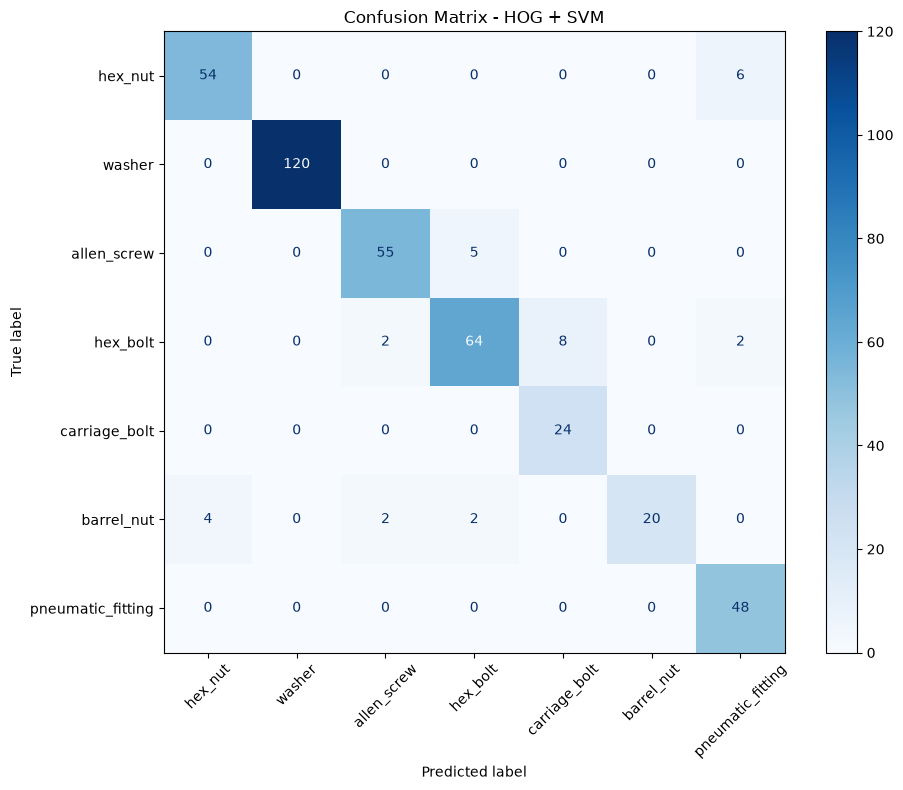

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=list(klassen.keys()),
    display_labels=list(klassen.values()),
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Confusion Matrix - HOG + SVM")
plt.tight_layout()
plt.show()

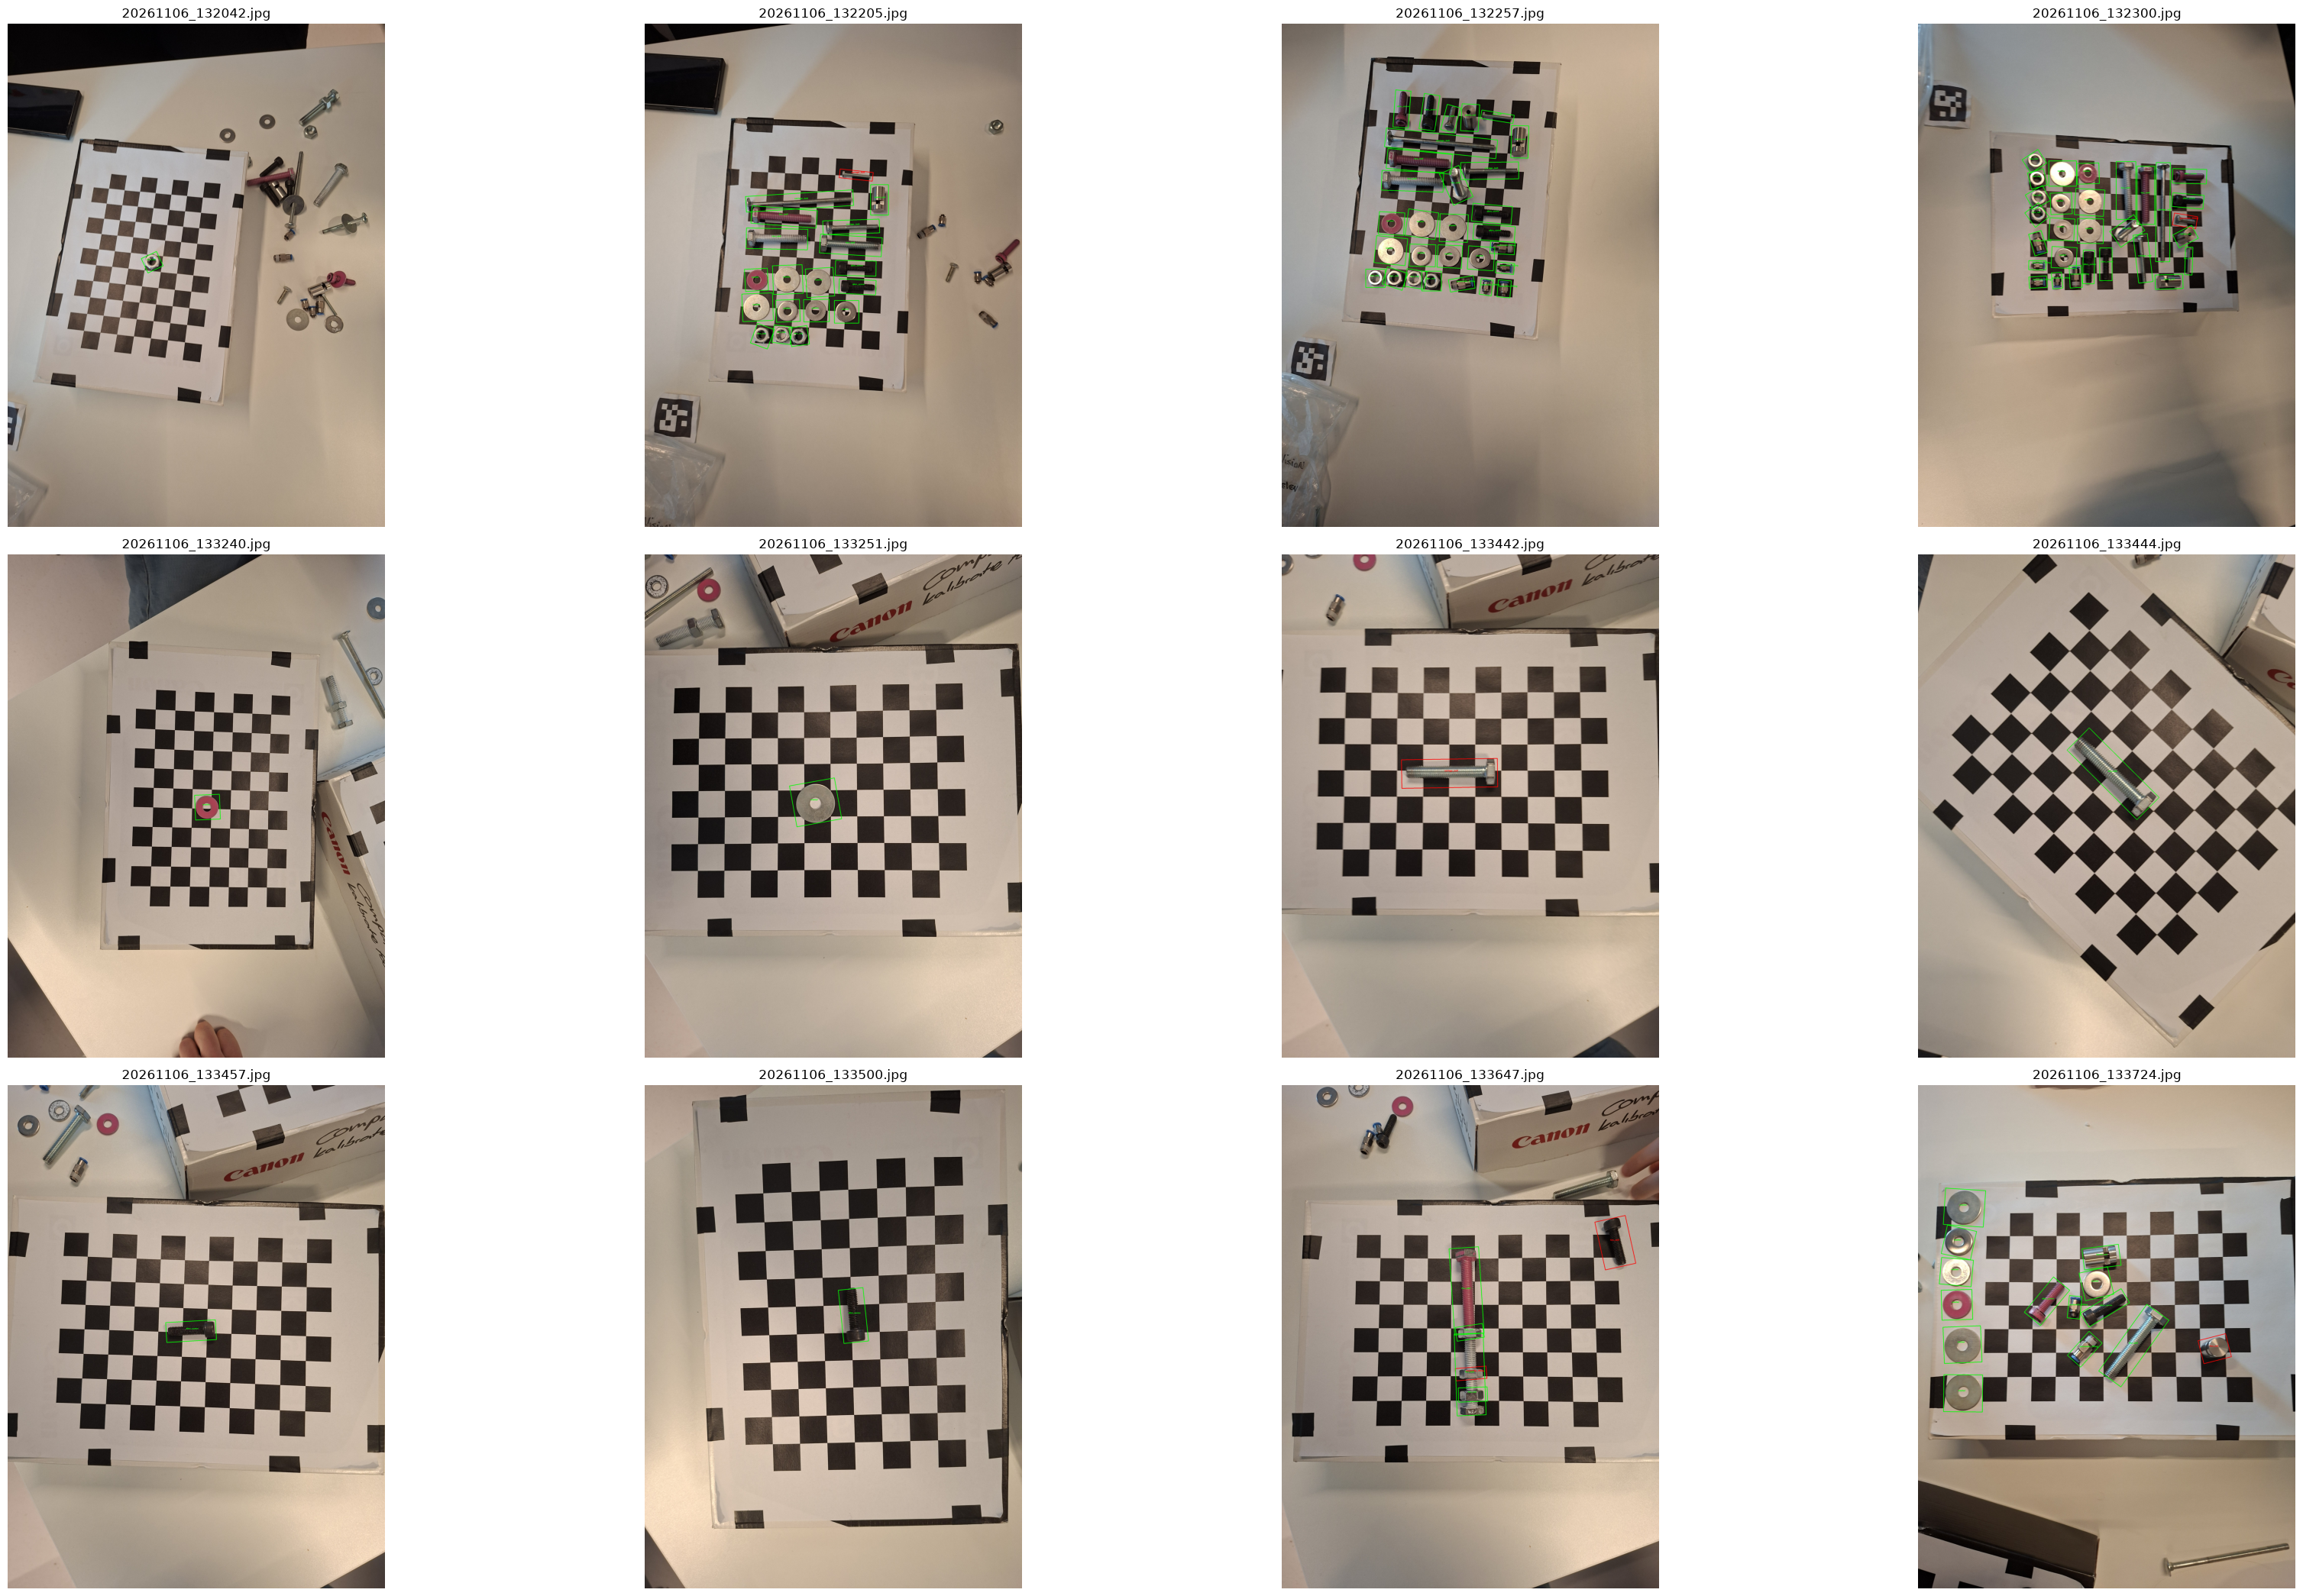

In [37]:
# Instellingen
aantal_fotos = 12
kolommen = 4

# Originele foto's uit de testgroepen selecteren
test_groepen = set(np.asarray(groepen)[test_idx])

fotos = [
    pad for pad in image_paths
    if pad.stem.removesuffix("_hv_flip")
               .removesuffix("_h_flip")
               .removesuffix("_v_flip") in test_groepen
]

# Kies één afbeelding per oorspronkelijke fotogroep
gekozen = []
gebruikte_groepen = set()

for pad in fotos:
    groep = (pad.stem.removesuffix("_hv_flip")
                     .removesuffix("_h_flip")
                     .removesuffix("_v_flip"))

    if groep not in gebruikte_groepen:
        gekozen.append(pad)
        gebruikte_groepen.add(groep)

gekozen = gekozen[:aantal_fotos]

fig, assen = plt.subplots(
    int(np.ceil(len(gekozen) / kolommen)),
    kolommen,
    figsize=(9 * kolommen, 7 * int(np.ceil(len(gekozen) / kolommen))),
    squeeze=False
)

for ax in assen.flat:
    ax.axis("off")

for ax, pad in zip(assen.flat, gekozen):

    img = cv2.imread(str(pad))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]
    resultaat = img.copy()

    label_pad = Path("dataset/labels") / (pad.stem + ".txt")

    if not label_pad.exists():
        continue

    with open(label_pad) as bestand:
        regels = bestand.readlines()

    for regel in regels:
        waarden = list(map(float, regel.split()))
        werkelijk = int(waarden[0])

        punten = np.array(waarden[1:9]).reshape(4, 2)
        punten[:, 0] *= w
        punten[:, 1] *= h
        punten = punten.astype(np.float32)

        # Onderdeel uitsnijden en HOG berekenen
        crop = crop_obb(img, punten)
        gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
        gray = cv2.resize(gray, (128, 128))

        kenmerken = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2)
        )

        voorspeld = int(model.predict([kenmerken])[0])

        # Groen = correct, rood = fout
        kleur = (0, 255, 0) if voorspeld == werkelijk else (255, 0, 0)

        cv2.polylines(
            resultaat,
            [punten.astype(np.int32)],
            True,
            kleur,
            3
        )

        x, y = punten.mean(axis=0).astype(int)

        cv2.putText(
            resultaat,
            klassen[voorspeld],
            (max(0, x - 40), max(20, y - 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            kleur,
            2
        )

    ax.imshow(resultaat)
    ax.set_title(pad.name)

plt.tight_layout()
plt.show()